In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/DailyDelhiClimateTrain.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print(df.head())
print("Total records:", len(df))
print(df.columns)

        date   meantemp   humidity  wind_speed  meanpressure
0 2013-01-01  10.000000  84.500000    0.000000   1015.666667
1 2013-01-02   7.400000  92.000000    2.980000   1017.800000
2 2013-01-03   7.166667  87.000000    4.633333   1018.666667
3 2013-01-04   8.666667  71.333333    1.233333   1017.166667
4 2013-01-05   6.000000  86.833333    3.700000   1016.500000
Total records: 1462
Index(['date', 'meantemp', 'humidity', 'wind_speed', 'meanpressure'], dtype='object')


In [3]:
features = ["meantemp", "humidity", "wind_speed", "meanpressure"]
df[features] = df[features].replace([np.inf, -np.inf], np.nan)
df.loc[~df["meanpressure"].between(900, 1100), "meanpressure"] = np.nan
df[features] = df[features].interpolate(limit_direction="both")
df = df.dropna(subset=features).reset_index(drop=True)
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
data = scaler.fit_transform(df[features])
print("Cleaned records:", len(df))
print("Data normalized successfully!")

Cleaned records: 1462
Data normalized successfully!


In [5]:
X, y = [], []
window = 7
temp_index = 0  # Index of 'meantemp' in features list
for i in range(window, len(data)):
    X.append(data[i-window:i])
    y.append(data[i, temp_index])
X = np.array(X)
y = np.array(y)
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1164, 7, 4)
Testing data: (291, 7, 4)


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
model = Sequential([
    LSTM(32, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    shuffle=False
)
print("Model training completed!")

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.1176 - val_loss: 0.0929
Epoch 2/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0488 - val_loss: 0.0267
Epoch 3/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0211 - val_loss: 0.0048
Epoch 4/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0119 - val_loss: 0.0039
Epoch 5/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0115 - val_loss: 0.0039
Model training completed!


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
pred = model.predict(X_test, verbose=0)
temp_col = 'meantemp'
temp_scaler = MinMaxScaler()
temp_scaler.fit(df[[temp_col]])
actual = temp_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()
predicted = temp_scaler.inverse_transform(
    pred
).flatten()
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 1.7
RMSE: 2.15


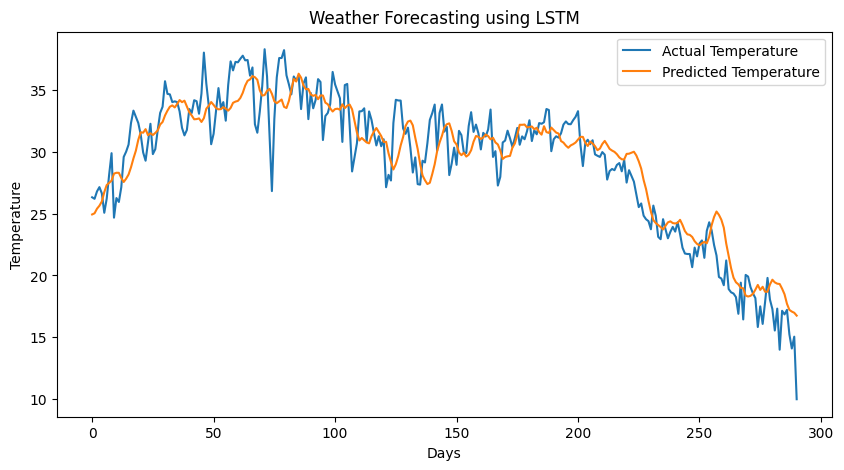

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(actual, label="Actual Temperature")
plt.plot(predicted, label="Predicted Temperature")
plt.xlabel("Days")
plt.ylabel("Temperature")
plt.title("Weather Forecasting using LSTM")
plt.legend()
plt.show()

In [11]:
last_sequence = data[-window:].copy()
future = []
for i in range(5):
    next_pred = model.predict(
        last_sequence.reshape(1, window, data.shape[1]),
        verbose=0
    )[0][0]
    future.append(next_pred)
    next_row = last_sequence[-1].copy()
    next_row[temp_index] = next_pred
    last_sequence = np.vstack([
        last_sequence[1:], next_row
    ])
future_temp = temp_scaler.inverse_transform(
    np.array(future).reshape(-1, 1)
).flatten()
print("Next 5 days forecast:")
for day, temp in enumerate(future_temp, 1):
    print(f"Day {day}: {temp:.2f} °C")

Next 5 days forecast:
Day 1: 16.16 °C
Day 2: 15.89 °C
Day 3: 15.55 °C
Day 4: 15.20 °C
Day 5: 15.05 °C
